In [8]:
import operator
from typing import Annotated, Literal, TypedDict

from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langchain_groq import ChatGroq
from langgraph.graph import END, START, StateGraph
from langgraph.checkpoint.memory import MemorySaver


In [ ]:
from langgraph.graph import add_messages

class ChatState(TypedDict):

    messages : Annotated[list[BaseMessage] , add_messages ]

In [4]:
llm = ChatGroq(model='openai/gpt-oss-20b')

def chatLLM (state : ChatState):

    # extract chat messgae 
    message = state['messages']

    # invoke the llm 
    response = llm.invoke(message)

    # add message to the list
    return {'messages' : [response]}

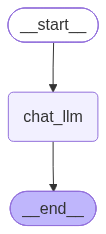

In [9]:
checkpointer = MemorySaver()
graph = StateGraph(ChatState)

# add nodes 
graph.add_node("chat_llm" , chatLLM)

# add edges 
graph.add_edge(START , 'chat_llm')
graph.add_edge('chat_llm' , END)
chatbot = graph.compile(checkpointer = checkpointer)
chatbot

In [7]:
initial_state = {
    'messages': [HumanMessage(content='What is the capital of india')]
}

chatbot.invoke(initial_state)['messages'][-1].content


'The capital of India is **New\u202fDelhi**.'

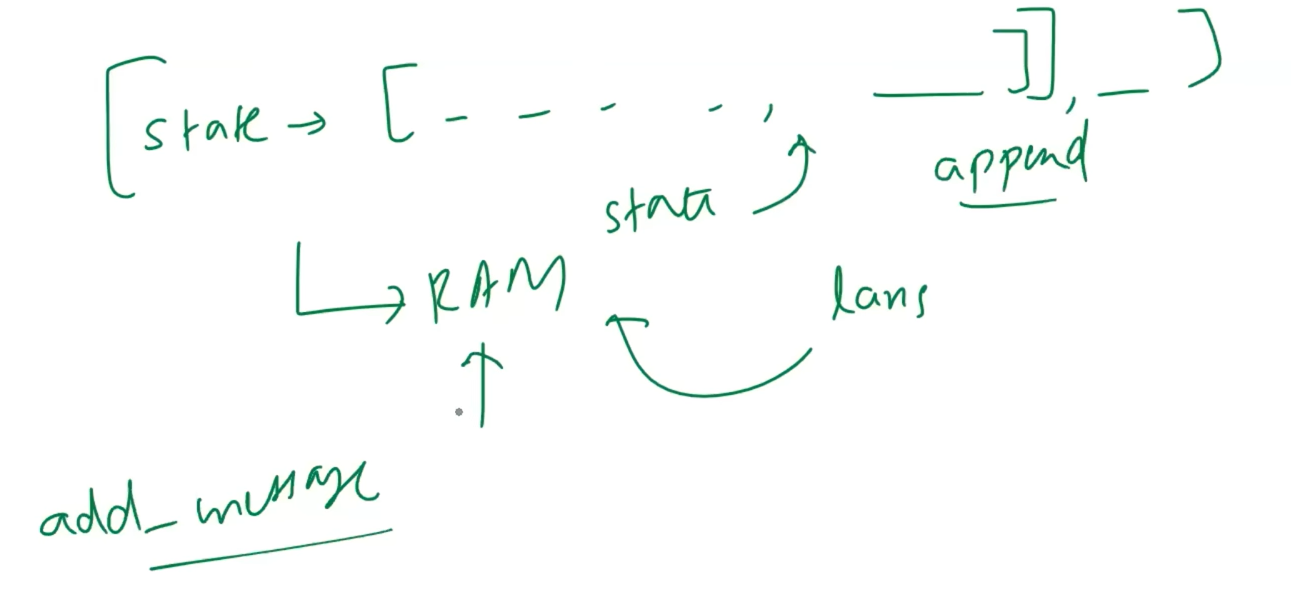

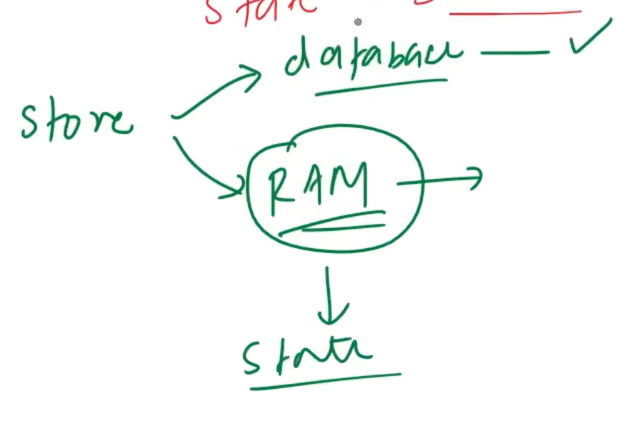

In [ ]:

thread_id = 1

while True:
    user_message = input('Type here : ')

    print('User : ' , user_message)

    if user_message.strip().lower() in ['exit' , 'quit' , 'bye']:
        break

    config = {'configurable' : {'thread_id' : thread_id}}
    response = chatbot.invoke({'messages' : HumanMessage(content  = user_message) } , config = config) 
    print('AI : ' , response['messages'][-1].content)

User :  hi my name is kapil
AI Hello Kapil! 👋 How can I assist you today?
User :  what is my name 
AI Your name is Kapil. If you’d like to add or change anything, just let me know!
User :  exit
